# Upload CSV

In [16]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

from google.colab import files

In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print(f"Đã đọc file: {file_name}")
print(f"Kích thước: {df.shape[0]:,} dòng x {df.shape[1]} cột")
df.head()

Saving chotot_xemay_named.csv to chotot_xemay_named.csv
Đã đọc file: chotot_xemay_named.csv
Kích thước: 30,563 dòng x 30 cột


,list_id,subject,body,price,price_string,regdate,mileage_v2,motorbikebrand,motorbikemodel,motorbiketype,...,is_price_not_valid,number_of_images,list_time,orig_list_time,crawl_date,brand_name,model_name,type_name,capacity_name,origin_name
0,135045712,"Honda SH 125cc biển Thần Tài 39.79 đẹp,êm du","SH 125cc biển đẹp Thần Tài. Nguyên bản,.giấy...",33000000,33.000.000 đ,2013,15000.0,1,19,1,...,False,6,1791057503000,NaN,2026-10-05,Honda,SH,Tay ga,100 - 175 cc,NaN
1,135027442,Honda SH 150 ABS 2020 Trắng 39000 km,SH 2020 150 ABS odo 3v9 ngon không có gì bàn c...,68888888,68.888.888 đ,2020,39000.0,1,19,1,...,False,3,1791011704168,1.790959e+12,2026-10-05,Honda,SH,Tay ga,100 - 175 cc,NaN
2,135024495,Honda Cub Cổ điển Trắng xanh,"Xe máy Honda Cub trắng xanh, kiểu dáng cổ điển...",5000000,5.000.000 đ,1999,150000.0,1,10,2,...,False,9,1790943110000,NaN,2026-10-05,Honda,Cub,Xe số,Không biết rõ,NaN
3,134916468,Yamaha R15 V3 Xanh lá Nhập khẩu,"Xe côn tay Yamaha R15 V3 màu xanh lá, kiểu dán...",26500000,26.500.000 đ,2019,10116.0,2,38,3,...,False,1,1790474382000,NaN,2026-10-05,Yamaha,Dòng khác,Tay côn/Moto,100 - 175 cc,Nước khác
4,134915720,Suzuki Hayate 125 Đen,"hayate 125 máy zin chất , khoẻ\ngiấy tờ đầy đủ...",2500000,2.500.000 đ,2015,16137.0,4,57,1,...,False,1,1790471628000,NaN,2026-10-05,Suzuki,Hayate,Tay ga,100 - 175 cc,NaN


In [3]:
# Keep original version
df_raw = df.copy()

# 1. Hình dạng và mẫu dữ liệu
print(f"Kích thước: {df.shape[0]:,} dòng x {df.shape[1]} cột\n")
display(df.head(5))

# 2. Tên cột, kiểu dữ liệu, số giá trị không thiếu
print("\n--- Thông tin cột ---")
df.info()

# 3. Tỉ lệ thiếu từng cột (chỉ hiện cột có thiếu)
missing = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
print("\n--- Tỉ lệ thiếu (%) ---")
print(missing[missing > 0])

# 4. Thống kê mô tả cho cột số
print("\n--- Thống kê cột số ---")
display(df.describe().T)

# 5. Số dòng trùng lặp
print(f"\nSố dòng trùng hoàn toàn: {df.duplicated().sum():,}")
print(f"Số list_id trùng: {df['list_id'].duplicated().sum():,}")

Kích thước: 30,563 dòng x 30 cột



,list_id,subject,body,price,price_string,regdate,mileage_v2,motorbikebrand,motorbikemodel,motorbiketype,...,is_price_not_valid,number_of_images,list_time,orig_list_time,crawl_date,brand_name,model_name,type_name,capacity_name,origin_name
0,135045712,"Honda SH 125cc biển Thần Tài 39.79 đẹp,êm du","SH 125cc biển đẹp Thần Tài. Nguyên bản,.giấy...",33000000,33.000.000 đ,2013,15000.0,1,19,1,...,False,6,1791057503000,NaN,2026-10-05,Honda,SH,Tay ga,100 - 175 cc,NaN
1,135027442,Honda SH 150 ABS 2020 Trắng 39000 km,SH 2020 150 ABS odo 3v9 ngon không có gì bàn c...,68888888,68.888.888 đ,2020,39000.0,1,19,1,...,False,3,1791011704168,1.790959e+12,2026-10-05,Honda,SH,Tay ga,100 - 175 cc,NaN
2,135024495,Honda Cub Cổ điển Trắng xanh,"Xe máy Honda Cub trắng xanh, kiểu dáng cổ điển...",5000000,5.000.000 đ,1999,150000.0,1,10,2,...,False,9,1790943110000,NaN,2026-10-05,Honda,Cub,Xe số,Không biết rõ,NaN
3,134916468,Yamaha R15 V3 Xanh lá Nhập khẩu,"Xe côn tay Yamaha R15 V3 màu xanh lá, kiểu dán...",26500000,26.500.000 đ,2019,10116.0,2,38,3,...,False,1,1790474382000,NaN,2026-10-05,Yamaha,Dòng khác,Tay côn/Moto,100 - 175 cc,Nước khác
4,134915720,Suzuki Hayate 125 Đen,"hayate 125 máy zin chất , khoẻ\ngiấy tờ đầy đủ...",2500000,2.500.000 đ,2015,16137.0,4,57,1,...,False,1,1790471628000,NaN,2026-10-05,Suzuki,Hayate,Tay ga,100 - 175 cc,NaN



--- Thông tin cột ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30563 entries, 0 to 30562
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   list_id             30563 non-null  int64  
 1   subject             30563 non-null  object 
 2   body                30563 non-null  object 
 3   price               30563 non-null  int64  
 4   price_string        30563 non-null  object 
 5   regdate             30563 non-null  int64  
 6   mileage_v2          30128 non-null  float64
 7   motorbikebrand      30563 non-null  int64  
 8   motorbikemodel      30563 non-null  int64  
 9   motorbiketype       30563 non-null  int64  
 10  motorbikecapacity   14982 non-null  float64
 11  motorbikeorigin     12809 non-null  float64
 12  condition_ad        30563 non-null  int64  
 13  condition_ad_name   30563 non-null  object 
 14  region_v2           30563 non-null  int64  
 15  region_name         30563 non-

,count,mean,std,min,25%,50%,75%,max
list_id,30563.0,1.336279e+08,4.556933e+06,4.765421e+07,1.341353e+08,1.345471e+08,1.348625e+08,1.350791e+08
price,30563.0,2.992385e+07,1.021412e+08,0.000000e+00,1.050000e+07,1.900000e+07,3.450000e+07,1.300000e+10
regdate,30563.0,2.016551e+03,2.121908e+01,0.000000e+00,2.013000e+03,2.018000e+03,2.022000e+03,2.026000e+03
mileage_v2,30128.0,3.576780e+04,9.783202e+04,0.000000e+00,3.849500e+03,1.500000e+04,3.000000e+04,1.000000e+06
motorbikebrand,30563.0,5.789288e+00,1.367795e+01,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,8.500000e+01
motorbikemodel,30563.0,1.324095e+02,1.842961e+02,0.000000e+00,1.900000e+01,2.500000e+01,2.790000e+02,9.060000e+02
motorbiketype,30563.0,1.723227e+00,9.087657e-01,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,4.000000e+00
motorbikecapacity,14982.0,2.844747e+00,7.497360e-01,0.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,5.000000e+00
motorbikeorigin,12809.0,3.218674e+00,2.545104e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00,1.000000e+01
condition_ad,30563.0,1.015116e+00,1.220176e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00



Số dòng trùng hoàn toàn: 0
Số list_id trùng: 0


In [4]:
# Phân phối các cột phân loại quan trọng
for col in ['condition_ad_name', 'type', 'is_price_not_valid',
            'brand_name', 'type_name', 'capacity_name', 'origin_name']:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))

# Dòng xe: bao nhiêu loại, và bao nhiêu tin là "Dòng khác"
print(f"\nSố dòng xe khác nhau: {df['model_name'].nunique()}")
print(f"Số tin 'Dòng khác': {(df['model_name'] == 'Dòng khác').sum():,}")


--- condition_ad_name ---
condition_ad_name
Đã sử dụng    30101
Mới             462
Name: count, dtype: int64

--- type ---
type
s    30563
Name: count, dtype: int64

--- is_price_not_valid ---
is_price_not_valid
False    30416
NaN        147
Name: count, dtype: int64

--- brand_name ---
brand_name
Honda       18565
Yamaha       5326
Piaggio      1690
Suzuki        882
VinFast       764
SYM           761
Kymco         259
Kawasaki      212
Detech        188
GPX           161
Name: count, dtype: int64

--- type_name ---
type_name
Tay ga          16664
Xe số            7050
Tay côn/Moto     5493
Xe máy điện      1356
Name: count, dtype: int64

--- capacity_name ---
capacity_name
NaN              15584
100 - 175 cc     11750
Dưới 50 cc        1502
Trên 175 cc        697
50 - 100 cc        690
Không biết rõ      340
Name: count, dtype: int64

--- origin_name ---
origin_name
NaN           17754
Việt Nam       6654
Nhật Bản       2758
Nước khác      1586
Thái Lan        960
Đài Loan        

# Kết luận trước khi làm sạch

1. Có 462 tin xe mới: cần lọc
2. Toàn bộ dữ liệu đều có `type = 's'`: không có tác dụng gì và cần loại bỏ
3. `is_price_not_valid` có 30416 false và 147 NaN, nhưng trước đó cho thấy min-max có thể đi từ 0 - 13 tỉ. Không hợp lý, không đáng tin cậy để sử dụng.
4. `capacity_name`, NaN và "Không biết rõ": nên gộp lại với nhau
5. Cần gộp các dòng xe, "Dòng khác" vào trong quá trình xử lý.

Số tin dùng để vẽ: 29,954 / 30,563
count        29954.0
mean      28221455.0
std       32031389.0
min        2000000.0
25%       10500000.0
50%       19500000.0
75%       34500000.0
max      500000000.0
Name: price, dtype: float64


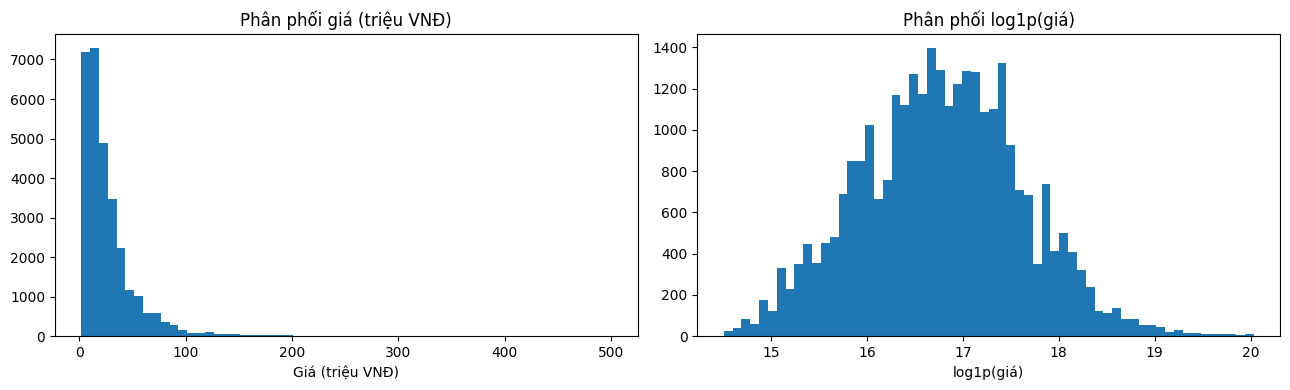

Độ lệch (skew) trước log: 5.19
Độ lệch (skew) sau log:   0.11


In [7]:
# Tạo df mới, lọc tạm xe mới và giá ngoài ngưỡng hợp lý (chưa sửa df gốc)
d = df[(df['condition_ad_name'] == 'Đã sử dụng') &
       (df['price'].between(2e6, 500e6))]

print(f"Số tin dùng để vẽ: {len(d):,} / {len(df):,}")
print(d['price'].describe().round(0))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(d['price'] / 1e6, bins=60)
ax[0].set_title('Phân phối giá (triệu VNĐ)')
ax[0].set_xlabel('Giá (triệu VNĐ)')

# Biểu đồ cho thấy right-skewed, và giá trị rất lớn.
# Dùng log(price+1) để

ax[1].hist(np.log1p(d['price']), bins=60)
ax[1].set_title('Phân phối log1p(giá)')
ax[1].set_xlabel('log1p(giá)')
plt.tight_layout()
plt.show()

print(f"Độ lệch (skew) trước log: {d['price'].skew():.2f}")
print(f"Độ lệch (skew) sau log:   {np.log1p(d['price']).skew():.2f}")

regdate < 1980: 1
mileage = 0: 770
mileage > 500,000: 330
mileage thiếu: 1

Số tin vẽ: 28,808


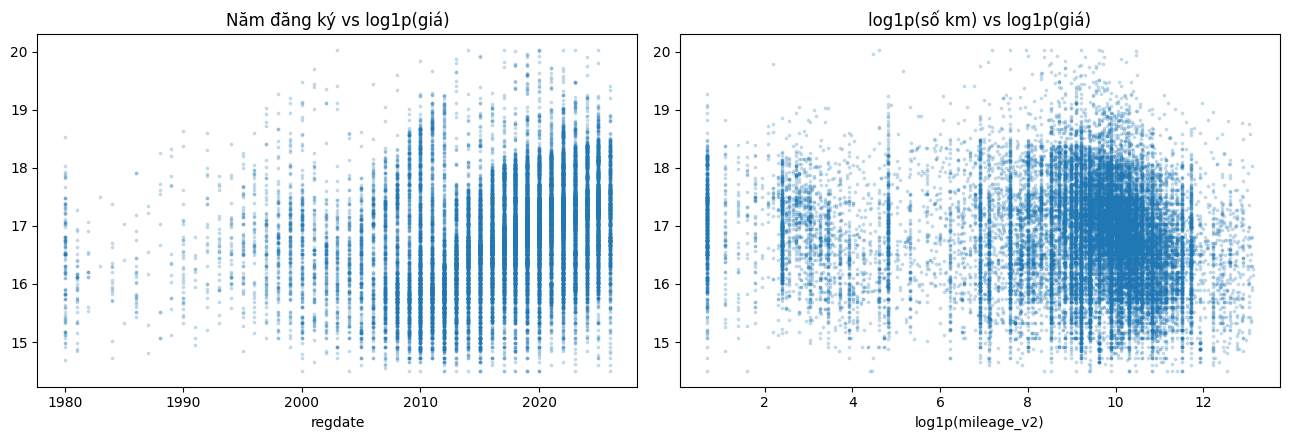


Tương quan Pearson với log1p(giá):
  regdate:    0.310
  mileage_v2: -0.140


In [8]:
d = df[(df['condition_ad_name'] == 'Đã sử dụng') &
       (df['price'].between(2e6, 500e6))].copy()

# Kiểm tra giá trị vô lý của năm và số km
print("regdate < 1980:", (d['regdate'] < 1980).sum())
print("mileage = 0:", (d['mileage_v2'] == 0).sum())
print("mileage > 500,000:", (d['mileage_v2'] > 500000).sum())
print("mileage thiếu:", d['mileage_v2'].isna().sum())

# Chỉ vẽ phần hợp lý
v = d[(d['regdate'] >= 1980) & (d['mileage_v2'] > 0) & (d['mileage_v2'] < 500000)]
print(f"\nSố tin vẽ: {len(v):,}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(v['regdate'], np.log1p(v['price']), s=3, alpha=0.2)
ax[0].set_title('Năm đăng ký vs log1p(giá)')
ax[0].set_xlabel('regdate')

ax[1].scatter(np.log1p(v['mileage_v2']), np.log1p(v['price']), s=3, alpha=0.2)
ax[1].set_title('log1p(số km) vs log1p(giá)')
ax[1].set_xlabel('log1p(mileage_v2)')
plt.tight_layout()
plt.show()

print("\nTương quan Pearson với log1p(giá):")
print(f"  regdate:    {v['regdate'].corr(np.log1p(v['price'])):.3f}")
print(f"  mileage_v2: {v['mileage_v2'].corr(np.log1p(v['price'])):.3f}")

In [9]:
top_models = v['model_name'].value_counts().head(6).index
print("Tương quan với log1p(giá) bên trong từng dòng xe:\n")
for m in top_models:
    s = v[v['model_name'] == m]
    r_year = s['regdate'].corr(np.log1p(s['price']))
    r_km = s['mileage_v2'].corr(np.log1p(s['price']))
    print(f"{m:<15} n={len(s):>5}  regdate: {r_year:.2f}   mileage: {r_km:.2f}")

Tương quan với log1p(giá) bên trong từng dòng xe:

Air Blade       n= 3050  regdate: 0.78   mileage: -0.19
SH              n= 2324  regdate: 0.30   mileage: -0.12
Wave            n= 1995  regdate: 0.16   mileage: -0.07
Vision          n= 1815  regdate: 0.74   mileage: -0.18
Exciter         n= 1697  regdate: -0.05   mileage: -0.03
Dòng khác       n= 1624  regdate: 0.01   mileage: -0.13


/tmp/ipykernel_1299/2296588928.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot([np.log1p(b[b['brand_name'] == x]['price']) for x in order_b],
/tmp/ipykernel_1299/2296588928.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1].boxplot([np.log1p(v[v['type_name'] == x]['price']) for x in order_t],


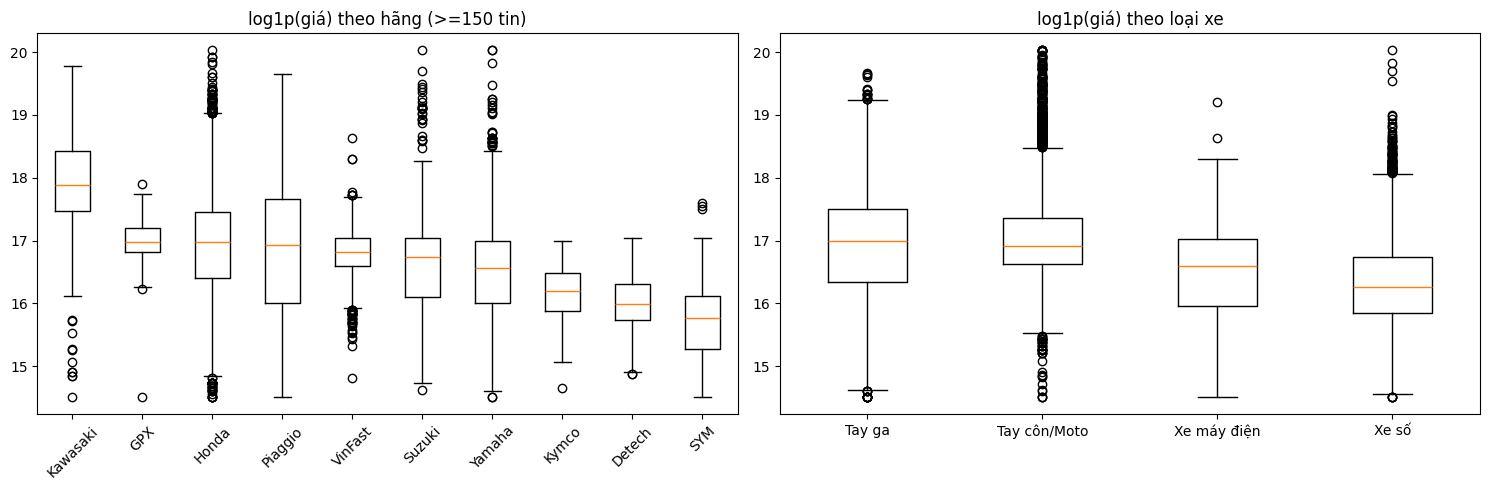

Giá trung vị (triệu VNĐ) theo hãng:
            median  count
brand_name               
Kawasaki      58.8    202
GPX           23.5    155
Honda         23.5  17601
Piaggio       22.5   1621
VinFast       20.0    669
Suzuki        18.5    829
Yamaha        15.5   5062
Kymco         10.8    254
Detech         8.8    161
SYM            7.0    731

Giá trung vị (triệu VNĐ) theo loại xe:
              median  count
type_name                  
Tay ga          24.0  15809
Tay côn/Moto    22.0   5240
Xe máy điện     16.0   1137
Xe số           11.5   6622


In [10]:
# Hãng có ít nhất 150 tin để boxplot đáng tin
brand_counts = v['brand_name'].value_counts()
top_brands = brand_counts[brand_counts >= 150].index
b = v[v['brand_name'].isin(top_brands)]

order_b = b.groupby('brand_name')['price'].median().sort_values(ascending=False).index
order_t = v.groupby('type_name')['price'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].boxplot([np.log1p(b[b['brand_name'] == x]['price']) for x in order_b],
              labels=order_b)
ax[0].set_title('log1p(giá) theo hãng (>=150 tin)')
ax[0].tick_params(axis='x', rotation=45)

ax[1].boxplot([np.log1p(v[v['type_name'] == x]['price']) for x in order_t],
              labels=order_t)
ax[1].set_title('log1p(giá) theo loại xe')
plt.tight_layout()
plt.show()

print("Giá trung vị (triệu VNĐ) theo hãng:")
print((b.groupby('brand_name')['price'].agg(['median', 'count'])
       .assign(median=lambda x: (x['median'] / 1e6).round(1))
       .loc[order_b]))
print("\nGiá trung vị (triệu VNĐ) theo loại xe:")
print((v.groupby('type_name')['price'].agg(['median', 'count'])
       .assign(median=lambda x: (x['median'] / 1e6).round(1))
       .loc[order_t]))

In [12]:
# ==========================================================
# LÀM SẠCH DỮ LIỆU (Data Cleaning)
#
# QUYẾT ĐỊNH VỀ SỐ KM: loại hẳn các tin có mileage_v2 = 0 (thay vì điền median).
# Lý do: đề tài chỉ dự đoán xe ĐÃ SỬ DỤNG, nên 0 km là thông tin không hợp lý
# (xe cũ đã chạy thì không thể 0 km). Giá trị này nhiều khả năng do người bán
# nhập bừa hoặc bỏ trống. Điền median sẽ đưa thêm giả định vào dữ liệu và làm
# số km mất tính phân biệt giữa các xe.
# Đánh đổi: mất khoảng 2,5% dữ liệu, chấp nhận được vì tập vẫn còn lớn (hàng
# chục nghìn mẫu).
# Tương tự, km > 500.000 và km thiếu cũng bị loại để dữ liệu nhất quán.
# ==========================================

df_clean = df_raw.copy()   # luôn làm trên bản sao, giữ nguyên dữ liệu gốc
log = []                   # lưu số dòng sau mỗi bước

def step(name, mask):
    """Giữ các dòng thỏa mask, ghi lại số dòng bị loại."""
    global df_clean
    before = len(df_clean)
    df_clean = df_clean[mask(df_clean)].copy()
    log.append({'Bước': name, 'Trước': before,
                'Bị loại': before - len(df_clean), 'Còn lại': len(df_clean)})

# 1. Chỉ giữ xe đã sử dụng (đề tài không dự đoán xe mới)
step('1. Loại xe "Mới"',
     lambda d: d['condition_ad_name'] == 'Đã sử dụng')

# 2. Lọc giá ảo bằng ngưỡng logic (cờ is_price_not_valid không bắt được giá ảo nào)
step('2. Giá ngoài 2 - 500 triệu',
     lambda d: d['price'].between(2e6, 500e6))

# 3. Năm đăng ký hợp lý
step('3. Năm đăng ký ngoài 1980 - 2026',
     lambda d: d['regdate'].between(1980, 2026))

# 4. Số km: loại thiếu, 0 km và trên 500.000 km (xem comment đầu cell)
step('4. Km thiếu / = 0 / > 500.000',
     lambda d: d['mileage_v2'].notna() & (d['mileage_v2'] > 0) & (d['mileage_v2'] <= 500000))

# 5. Tin đăng lại: cùng tiêu đề, giá, năm, km (list_id đã không trùng từ trước)
dup_cols = ['subject', 'price', 'regdate', 'mileage_v2']
step('5. Tin trùng (subject, price, regdate, km)',
     lambda d: ~d.duplicated(subset=dup_cols, keep='first'))

# Bảng tổng kết
log_df = pd.DataFrame(log)
display(log_df)
print(f"\nDữ liệu gốc: {len(df_raw):,} dòng")
print(f"Sau làm sạch: {len(df_clean):,} dòng "
      f"({len(df_clean) / len(df_raw) * 100:.1f}% giữ lại, "
      f"bị loại {len(df_raw) - len(df_clean):,})")

,Bước,Trước,Bị loại,Còn lại
0,"1. Loại xe ""Mới""",30563,462,30101
1,2. Giá ngoài 2 - 500 triệu,30101,147,29954
2,3. Năm đăng ký ngoài 1980 - 2026,29954,1,29953
3,4. Km thiếu / = 0 / > 500.000,29953,1100,28853
4,"5. Tin trùng (subject, price, regdate, km)",28853,56,28797



Dữ liệu gốc: 30,563 dòng
Sau làm sạch: 28,797 dòng (94.2% giữ lại, bị loại 1,766)


In [13]:
# 1. Kiểm tra lại phân phối sau làm sạch
print(df_clean[['price', 'regdate', 'mileage_v2']].describe().round(0))
print(f"\nSkew giá: {df_clean['price'].skew():.2f} -> sau log: {np.log1p(df_clean['price']).skew():.2f}")

# 2. Lưu bản sạch (bước này là mốc 'dữ liệu sạch' để bàn giao)
df_clean.to_csv('chotot_xemay_clean.csv', index=False, encoding='utf-8-sig')
print(f"\nĐã lưu chotot_xemay_clean.csv: {len(df_clean):,} dòng x {df_clean.shape[1]} cột")

# 3. Tải về máy (Colab)
from google.colab import files
files.download('chotot_xemay_clean.csv')

             price  regdate  mileage_v2
count      28797.0  28797.0     28797.0
mean    28219549.0   2017.0     27640.0
std     31813386.0      7.0     47847.0
min      2000000.0   1980.0         1.0
25%     10700000.0   2013.0      5000.0
50%     19500000.0   2018.0     15000.0
75%     34500000.0   2022.0     30000.0
max    500000000.0   2026.0    500000.0

Skew giá: 5.19 -> sau log: 0.11

Đã lưu chotot_xemay_clean.csv: 28,797 dòng x 30 cột


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# ==========================================================
# SỬA NHÃN "Dòng khác" BẰNG REGEX TRÊN TIÊU ĐỀ
#
# Vấn đề: ~5,6% tin bị gán "Dòng khác", làm mất thông tin về dòng xe
# (tương quan tuổi-giá trong nhóm này ~0, vì trộn nhiều loại xe khác nhau).
#
# Quy tắc (rút ra từ việc kiểm tra mẫu thực tế):
#  1. Chỉ gán tên dòng khi HÃNG KHỚP với dòng đó (vd. Wave -> Honda).
#     Lý do: nhiều hãng nhỏ (Việt Thái, Halim, Motor Thái...) mượn tên
#     Wave/Sirius/Dream để đặt cho xe nhái 50cc giá vài triệu. Bản đầu không
#     có ràng buộc này đã gán nhầm ~75 tin vào "Wave".
#  2. Tin còn lại có "50cc/49cc" -> nhóm "Xe 50cc" (phân khúc giá riêng, trung vị ~9 triệu).
#  3. Còn lại giữ "Dòng khác" (tiêu đề thiếu thông tin, hoặc dòng quá hiếm).
#
# Giữ nguyên "Custom": đã kiểm tra 17 tin, đều là Honda Custom thật. Giá cao
# (trung vị ~68 triệu) vì là xe Nhật cổ đời 1998-2000, hàng sưu tầm, không phải lỗi regex.
#
# Cột gốc model_name được giữ nguyên, kết quả ghi vào cột mới model_fixed
# (để so sánh trước/sau và truy ngược được nếu regex sai).
# ==========================================================

# (regex, tên dòng chuẩn, hãng gốc). Thứ tự quan trọng: cụm cụ thể trước cụm chung
# (vd. "winner" phải đứng trước "win").
MODEL_RULES = [
    (r'\bexciter\b',            'Exciter',   'Yamaha'),
    (r'\bwinner\b',             'Winner',    'Honda'),
    (r'\bsirius\b',             'Sirius',    'Yamaha'),
    (r'\bair\s*blade\b|\bab\b', 'Air Blade', 'Honda'),
    (r'\bvision\b',             'Vision',    'Honda'),
    (r'\bjanus\b',              'Janus',     'Yamaha'),
    (r'\bjupiter\b',            'Jupiter',   'Yamaha'),
    (r'\blead\b',               'Lead',      'Honda'),
    (r'\bfuture\b',             'Future',    'Honda'),
    (r'\bdream\b',              'Dream',     'Honda'),
    (r'\bchaly\b',              'Chaly',     'Honda'),
    (r'\bcustom\b',             'Custom',    'Honda'),
    (r'\bcub\b|\bcúp\b',        'Cub',       'Honda'),
    (r'\bwave\b',               'Wave',      'Honda'),
    (r'\bwin\b',                'Win',       'Honda'),
    (r'\bsh\b',                 'SH',        'Honda'),
]
MODEL_RULES = [(re.compile(p), name, brand) for p, name, brand in MODEL_RULES]
PATTERN_50CC = re.compile(r'\b(?:49|50)\s*(?:cc|cm3)\b')


def infer_model(subject, brand):
    """Đoán dòng xe từ tiêu đề cho một tin đang là 'Dòng khác'."""
    text = str(subject).lower()
    for pattern, name, expected_brand in MODEL_RULES:
        if brand == expected_brand and pattern.search(text):
            return name
    if PATTERN_50CC.search(text):
        return 'Xe 50cc'
    return 'Dòng khác'


# --- Áp dụng: chỉ động vào các tin đang là "Dòng khác" ---
is_other = df_clean['model_name'] == 'Dòng khác'
df_clean['model_fixed'] = df_clean['model_name']
df_clean.loc[is_other, 'model_fixed'] = [
    infer_model(s, b)
    for s, b in zip(df_clean.loc[is_other, 'subject'], df_clean.loc[is_other, 'brand_name'])
]

# --- Báo cáo ---
still_other = df_clean['model_fixed'] == 'Dòng khác'
fixed = df_clean[is_other & ~still_other]
print(f"'Dòng khác': {is_other.sum():,} -> {still_other.sum():,}  "
      f"(sửa {len(fixed):,} tin, {len(fixed) / is_other.sum() * 100:.1f}%)")
print("\nTên dòng mới gán:")
print(fixed['model_fixed'].value_counts())

# --- Kiểm chứng: giá trung vị nhóm mới gán có khớp nhóm gốc cùng tên không? ---
# Khớp (lệch < ~20%) => gán hợp lý. Lệch lớn => cần xem lại hoặc giải thích được
# (vd. Winner mới gán toàn đời V3 2022-2023 nên đắt hơn nhóm gốc nhiều đời cũ).
print("\nTrung vị giá (triệu VNĐ): mới gán vs gốc cùng tên")
for name in fixed['model_fixed'].value_counts().head(8).index:
    new = fixed.loc[fixed['model_fixed'] == name, 'price'].median() / 1e6
    old = df_clean.loc[df_clean['model_name'] == name, 'price'].median() / 1e6
    print(f"  {name:<10} mới: {new:5.1f}   gốc: {old:5.1f}")

'Dòng khác': 1,624 -> 1,144  (sửa 480 tin, 29.6%)

Tên dòng mới gán:
model_fixed
Xe 50cc      376
Exciter       23
Air Blade     20
Custom        17
Winner        11
Wave          10
Future         5
Cub            5
Dream          4
Jupiter        3
Sirius         2
Vision         1
Lead           1
Chaly          1
Win            1
Name: count, dtype: int64

Trung vị giá (triệu VNĐ): mới gán vs gốc cùng tên
  Xe 50cc    mới:   8.8   gốc:   nan
  Exciter    mới:  15.5   gốc:  18.5
  Air Blade  mới:  27.6   gốc:  19.8
  Custom     mới:  68.0   gốc:   nan
  Winner     mới:  23.0   gốc:  15.8
  Wave       mới:  10.9   gốc:  10.5
  Future     mới:  27.5   gốc:  25.0
  Cub        mới:  10.0   gốc:   8.9


In [23]:
# ==========================================================
# ĐỐI CHIẾU regdate VỚI NĂM GHI TRONG TIÊU ĐỀ
#
# Phát hiện: ~62% tin có năm trong tiêu đề, phần lớn khớp regdate.
# Chỉ 292 tin (~1%) lệch >= 5 năm, chia hai nhóm bản chất khác nhau:
#
#  (a) Tiêu đề MỚI hơn regdate (245 tin): regdate ĐÚNG, tiêu đề ghi sai.
#      Bằng chứng: giá / trung vị giá cùng dòng cùng regdate có trung vị = 1,0
#      (vd. "Air Blade 2025" regdate 2011, giá 3,9 triệu - giá hợp xe 2011).
#      Nguyên nhân (giả thuyết): người bán ghi năm đăng tin / "đời mới" để câu khách.
#      => KHÔNG sửa regdate theo tiêu đề (sẽ phá quan hệ tuổi-giá). GIỮ nguyên.
#
#  (b) Tiêu đề CŨ hơn regdate (47 tin): hai nguồn mâu thuẫn, nhiều trường hợp
#      không xác định được bên đúng (vd. "Honda ab 2008", regdate 2022, giá hợp 2008).
#      => LOẠI.
# ==========================================================

# Tách năm 1980-2029 khỏi tiêu đề, bỏ qua số đi kèm "km"/"cc"
# (tránh đọc "Winindo 125 ... 2000 km" thành năm 2000).
YEAR_REGEX = r'\b((?:19[89]|20[0-2])\d)\b(?!\s*(?:km|cc))'
df_clean['year_title'] = (df_clean['subject']
                          .str.extract(YEAR_REGEX, flags=re.I)[0]
                          .astype(float))

# gap > 0: tiêu đề cũ hơn regdate | gap < 0: tiêu đề mới hơn regdate
gap = df_clean['regdate'] - df_clean['year_title']
has_year = df_clean['year_title'].notna()

print(f"Tin có năm trong tiêu đề: {has_year.sum():,} ({has_year.mean() * 100:.1f}%)")
for k in (1, 3, 5):
    print(f"  Lệch >= {k} năm: {(gap.abs() >= k).sum():,}")
print(f"\nLệch >= 5 năm, theo hướng:")
print(f"  Tiêu đề MỚI hơn regdate (giữ): {(gap <= -5).sum():,}")
print(f"  Tiêu đề CŨ hơn regdate (loại): {(gap >= 5).sum():,}")

# --- Loại nhóm (b) ---
n0 = len(df_clean)
df_clean = df_clean[~(gap >= 5)].copy()
log.append({'Bước': '6. Tiêu đề cũ hơn regdate >= 5 năm',
            'Trước': n0, 'Bị loại': n0 - len(df_clean), 'Còn lại': len(df_clean)})

# --- Loại tin đăng lại ---
# Bước 5 trước đó dùng thêm số km nên bỏ sót tin đăng lại mà người bán nhập km khác
# (vd. 2 tin "SH 300i 2007, 95 triệu"). Ở đây bỏ km khỏi khóa.
n1 = len(df_clean)
df_clean = df_clean[~df_clean.duplicated(subset=['subject', 'price', 'regdate'],
                                         keep='first')].copy()
log.append({'Bước': '7. Tin trùng (subject, price, regdate)',
            'Trước': n1, 'Bị loại': n1 - len(df_clean), 'Còn lại': len(df_clean)})

# year_title chỉ là cột trung gian để kiểm tra, không dùng làm feature
df_clean = df_clean.drop(columns=['year_title'])

display(pd.DataFrame(log))
print(f"\nSau làm sạch: {len(df_clean):,} dòng "
      f"({len(df_clean) / len(df_raw) * 100:.1f}% dữ liệu gốc)")

Tin có năm trong tiêu đề: 17,855 (62.0%)
  Lệch >= 1 năm: 973
  Lệch >= 3 năm: 429
  Lệch >= 5 năm: 280

Lệch >= 5 năm, theo hướng:
  Tiêu đề MỚI hơn regdate (giữ): 245
  Tiêu đề CŨ hơn regdate (loại): 35


,Bước,Trước,Bị loại,Còn lại
0,"1. Loại xe ""Mới""",30563,462,30101
1,2. Giá ngoài 2 - 500 triệu,30101,147,29954
2,3. Năm đăng ký ngoài 1980 - 2026,29954,1,29953
3,4. Km thiếu / = 0 / > 500.000,29953,1100,28853
4,"5. Tin trùng (subject, price, regdate, km)",28853,56,28797
5,6. Tiêu đề cũ hơn regdate >= 5 năm,28797,35,28762
6,"7. Tin trùng (subject, price, regdate)",28762,103,28659



Sau làm sạch: 28,659 dòng (93.8% dữ liệu gốc)


In [24]:
# ==========================================================
# FEATURE ENGINEERING
# Các cột thô được giữ nguyên, feature mới ghi vào cột mới.
# ==========================================================
REF_YEAR = 2026

# --- 1. Thiếu / "không biết rõ" -> một nhãn thống nhất "Không rõ" ---
# Thiếu dung tích 51%, xuất xứ 58%: không bỏ dòng (mất quá nhiều mẫu),
# coi "không điền" cũng là một thông tin.
df_clean['capacity_fixed'] = (df_clean['capacity_name']
                              .replace('Không biết rõ', np.nan).fillna('Không rõ'))
df_clean['origin_fixed'] = df_clean['origin_name'].fillna('Không rõ')

# Xuất xứ hiếm (< 100 tin) gộp thành "Khác"
rare_origin = df_clean['origin_fixed'].value_counts()
rare_origin = rare_origin[rare_origin < 100].index
df_clean['origin_fixed'] = df_clean['origin_fixed'].replace(dict.fromkeys(rare_origin, 'Khác'))

# --- 2. Gộp dòng xe hiếm (< 20 tin) thành "Khác" ---
# Tránh quá khớp trên nhóm quá ít mẫu. Giữ riêng "Dòng khác" và "Xe 50cc".
cnt = df_clean['model_fixed'].value_counts()
rare_models = cnt[(cnt < 20) & ~cnt.index.isin(['Dòng khác', 'Xe 50cc'])].index
df_clean['model_grouped'] = df_clean['model_fixed'].replace(dict.fromkeys(rare_models, 'Khác'))

# --- 3. Feature số ---
df_clean['tuoi_xe'] = REF_YEAR - df_clean['regdate']
# Xe đăng ký năm nay có tuổi 0 -> dùng max(tuổi, 1) để tránh chia cho 0
df_clean['km_moi_nam'] = df_clean['mileage_v2'] / df_clean['tuoi_xe'].clip(lower=1)
df_clean['log_price'] = np.log1p(df_clean['price'])   # biến mục tiêu khi train

# --- 4. Cờ từ khóa trong tiêu đề + mô tả ---
text = (df_clean['subject'].fillna('') + ' ' + df_clean['body'].fillna('')).str.lower()
KEYWORDS = {
    'flag_chinh_chu': r'chính chủ',
    'flag_zin':       r'\bzin\b|nguyên bản',
    'flag_bien_dep':  r'biển (?:số )?đẹp|ngũ quý|tứ quý|lộc phát|thần tài|sảnh tiến',
}
for col, pattern in KEYWORDS.items():
    df_clean[col] = text.str.contains(pattern, regex=True).astype(int)

# --- Báo cáo ---
print(f"Số dòng xe: {df_clean['model_fixed'].nunique()} -> {df_clean['model_grouped'].nunique()} sau khi gộp")
print(f"Dòng xe bị gộp vào 'Khác': {len(rare_models)}")
print("\nCapacity:\n", df_clean['capacity_fixed'].value_counts())
print("\nOrigin:\n", df_clean['origin_fixed'].value_counts())
print("\nTỉ lệ tin có cờ từ khóa:")
print(df_clean[list(KEYWORDS)].mean().round(3))
print("\nThống kê feature số:")
print(df_clean[['tuoi_xe', 'km_moi_nam']].describe().round(1))

Số dòng xe: 409 -> 118 sau khi gộp
Dòng xe bị gộp vào 'Khác': 292

Capacity:
 capacity_fixed
Không rõ        14822
100 - 175 cc    11160
Dưới 50 cc       1402
50 - 100 cc       644
Trên 175 cc       631
Name: count, dtype: int64

Origin:
 origin_fixed
Không rõ      16839
Việt Nam       6149
Nhật Bản       2613
Nước khác      1434
Thái Lan        901
Đài Loan        260
Trung Quốc      204
Hàn Quốc        171
Khác             88
Name: count, dtype: int64

Tỉ lệ tin có cờ từ khóa:
flag_chinh_chu    0.347
flag_zin          0.504
flag_bien_dep     0.008
dtype: float64

Thống kê feature số:
       tuoi_xe  km_moi_nam
count  28659.0     28659.0
mean       9.3      3987.2
std        7.1      9378.1
min        0.0         0.0
25%        4.0       823.0
50%        8.0      2250.0
75%       13.0      4250.0
max       46.0    500000.0


In [25]:
# 1. km_moi_nam bất thường
print("km_moi_nam > 30.000:", (df_clean['km_moi_nam'] > 30000).sum())
display(df_clean.loc[df_clean['km_moi_nam'] > 30000,
        ['subject', 'regdate', 'mileage_v2', 'km_moi_nam', 'price']]
        .sort_values('km_moi_nam', ascending=False).head(10))

# 2. Các cờ có thật sự liên quan đến giá không? (trung vị giá, triệu VNĐ)
for f in ['flag_chinh_chu', 'flag_zin', 'flag_bien_dep']:
    g = df_clean.groupby(f)['price'].agg(['median', 'count'])
    g['median'] = (g['median'] / 1e6).round(1)
    print(f"\n{f}:\n{g}")

# 3. Ma trận tương quan các biến số
num = ['log_price', 'tuoi_xe', 'mileage_v2', 'km_moi_nam',
       'flag_chinh_chu', 'flag_zin', 'flag_bien_dep']
display(df_clean[num].corr().round(2))

km_moi_nam > 30.000: 358


,subject,regdate,mileage_v2,km_moi_nam,price
1189,"Vision 2026 Màu Nâu Nhám bs Hà Nội, Chính Chủ",2026,500000.0,500000.0,30800000
1333,Honda Hness CB350 Xám Nhập khẩu,2025,470000.0,470000.0,118000000
24524,Xe máy điện VinFast VeroX màu Đen,2025,345678.0,345678.0,27000000
2164,Honda Click Đen Xe tay ga,2026,300000.0,300000.0,4000000
2298,wave 110đen 2024 biển 8886,2024,450000.0,225000.0,22000000
18243,Yadea Orris Xám ken lên ic 80km,2024,440000.0,220000.0,14500000
20556,Honda Wave 110 2025 Đỏ 215464 km,2025,215464.0,215464.0,12500000
7818,"Victoria AT69 Xanh dương, Trắng",2024,400000.0,200000.0,12800000
10222,Honda SH Ý 103 153 cm3 Trắng 191.703 km,2026,191703.0,191703.0,86000000
9030,Honda Air Blade 125 ABS 2026 Xám đỏ,2026,180000.0,180000.0,48000000



flag_chinh_chu:
                median  count
flag_chinh_chu               
0                 16.9  18701
1                 24.5   9958

flag_zin:
          median  count
flag_zin               
0           16.5  14227
1           22.5  14432

flag_bien_dep:
               median  count
flag_bien_dep               
0                19.5  28417
1                29.5    242


,log_price,tuoi_xe,mileage_v2,km_moi_nam,flag_chinh_chu,flag_zin,flag_bien_dep
log_price,1.00,-0.31,-0.14,0.01,0.18,0.18,0.05
tuoi_xe,-0.31,1.00,0.19,-0.14,-0.13,-0.08,0.03
mileage_v2,-0.14,0.19,1.00,0.58,-0.04,-0.03,-0.00
km_moi_nam,0.01,-0.14,0.58,1.00,0.01,-0.02,-0.01
flag_chinh_chu,0.18,-0.13,-0.04,0.01,1.00,0.14,0.00
flag_zin,0.18,-0.08,-0.03,-0.02,0.14,1.00,0.01
flag_bien_dep,0.05,0.03,-0.00,-0.01,0.00,0.01,1.00


In [26]:
# QUYẾT ĐỊNH: loại tin có km/năm > 30.000.
# Lý do: 358 tin (1,2%) có mẫu rõ ràng là lỗi nhập liệu: xe đời 2024-2026 giá còn cao
# nhưng khai 200.000-500.000 km, hoặc dãy số bừa (345678), hoặc tiêu đề ghi vài chục km.
# Ngưỡng 500.000 km ở bước 4 quá lỏng; lọc theo km/năm chặt hơn vì tính cả tuổi xe.
n0 = len(df_clean)
df_clean = df_clean[df_clean['km_moi_nam'] <= 30000].copy()
log.append({'Bước': '8. Km/năm > 30.000',
            'Trước': n0, 'Bị loại': n0 - len(df_clean), 'Còn lại': len(df_clean)})
display(pd.DataFrame(log))

print("\nTương quan với log_price sau khi lọc:")
print(df_clean[['tuoi_xe', 'mileage_v2', 'km_moi_nam']]
      .corrwith(df_clean['log_price']).round(3))
print(f"\nkm_moi_nam: max = {df_clean['km_moi_nam'].max():,.0f}, "
      f"mean = {df_clean['km_moi_nam'].mean():,.0f}, "
      f"median = {df_clean['km_moi_nam'].median():,.0f}")

,Bước,Trước,Bị loại,Còn lại
0,"1. Loại xe ""Mới""",30563,462,30101
1,2. Giá ngoài 2 - 500 triệu,30101,147,29954
2,3. Năm đăng ký ngoài 1980 - 2026,29954,1,29953
3,4. Km thiếu / = 0 / > 500.000,29953,1100,28853
4,"5. Tin trùng (subject, price, regdate, km)",28853,56,28797
5,6. Tiêu đề cũ hơn regdate >= 5 năm,28797,35,28762
6,"7. Tin trùng (subject, price, regdate)",28762,103,28659
7,8. Km/năm > 30.000,28659,358,28301



Tương quan với log_price sau khi lọc:
tuoi_xe      -0.312
mileage_v2   -0.158
km_moi_nam    0.030
dtype: float64

km_moi_nam: max = 30,000, mean = 3,263, median = 2,222


In [27]:
# Chọn cột bàn giao: bỏ cột trung gian / không dùng, giữ cột gốc để truy vết
drop_cols = ['price_string', 'type', 'orig_list_time', 'is_price_not_valid']
out = df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns])

out.to_csv('chotot_xemay_clean.csv', index=False, encoding='utf-8-sig')
print(f"Đã lưu: {len(out):,} dòng x {out.shape[1]} cột")
print(list(out.columns))

files.download('chotot_xemay_clean.csv')

Đã lưu: 28,301 dòng x 36 cột
['list_id', 'subject', 'body', 'price', 'regdate', 'mileage_v2', 'motorbikebrand', 'motorbikemodel', 'motorbiketype', 'motorbikecapacity', 'motorbikeorigin', 'condition_ad', 'condition_ad_name', 'region_v2', 'region_name', 'area_v2', 'area_name', 'ward_name', 'number_of_images', 'list_time', 'crawl_date', 'brand_name', 'model_name', 'type_name', 'capacity_name', 'origin_name', 'model_fixed', 'capacity_fixed', 'origin_fixed', 'model_grouped', 'tuoi_xe', 'km_moi_nam', 'log_price', 'flag_chinh_chu', 'flag_zin', 'flag_bien_dep']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>